# Batch Digester Analysis (D1–D4)

Reads the data saved by `pull_data.py` (no PI access here), splits it into batches, calculates the H-factor per batch and compares the 4 digesters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from pull_data import load_data
from batch import all_phase_tables, build_batch_table
from hfactor import h_factor_per_batch

sns.set_theme(style="whitegrid")

## 1. Load saved data

In [2]:
DATA_NAME = f"digester_{config.START_TIME[:10]}_{config.END_TIME[:10]}"
df = load_data(DATA_NAME)
print(df.shape, df.index.min(), df.index.max())
df.head()

(17569, 99) 2026-08-01 00:00:00 2026-10-01 00:00:00


,black_liquor_conductivity,D1_batch_number,D1_pfactor_setpoint,D1_pfactor_actual,D2_batch_number,D2_pfactor_setpoint,D2_pfactor_actual,D3_batch_number,D3_pfactor_setpoint,D3_pfactor_actual,...,D4_ventilation_temp,D4_displacement_liquor_temp,D4_chip_weight,D1_press1_status,D2_press1_status,D3_press1_status,D4_press1_status,press1_brightness,press1_kappa,press1_viscosity
timestamp,,,,,,,,,,,,,,,,,,,,,
2026-08-01 00:00:00,88.296875,8910,320,485.676392,8912,320,153.856216,8911,320,353.069519,...,90.0,100.197533,20.726858,0.060105,2.0,0.106690,0.0,35.000000,9.00000,816.000000
2026-08-01 00:05:00,88.296875,8910,320,485.679016,8912,320,174.696579,8911,320,353.069519,...,90.0,98.630981,30.940813,0.061873,2.0,0.102824,0.0,34.962502,9.03125,815.291687
2026-08-01 00:10:00,88.296875,8910,320,485.681671,8912,320,197.454712,8911,320,353.069519,...,90.0,97.064430,41.154766,0.063641,2.0,0.098958,0.0,34.924999,9.06250,814.583313
2026-08-01 00:15:00,88.296875,8910,320,485.684296,8912,320,222.423965,8911,320,353.069519,...,90.0,95.497879,51.368721,0.065409,2.0,0.095093,0.0,34.887501,9.09375,813.875000
2026-08-01 00:20:00,88.296875,8910,320,485.686920,8912,320,247.992493,8911,320,353.069519,...,90.0,93.931320,61.582676,0.067176,2.0,0.091227,0.0,34.849998,9.12500,813.166687


## 2. Phase table and batch table

In [3]:
phases = all_phase_tables(df)
batches = build_batch_table(phases)

print("Phases seen:", phases["phase"].unique())
print("Batches per digester:")
print(batches["digester"].value_counts().sort_index())
batches.head()

Phases seen: <StringArray>
[      'DISPLACEMENT',          'DISCHARGE',       'CHIP FILLING',
          'PREHYDRAU', 'HOT LIQUOR FILLING',          'HEAT&COOK',
               'WAIT',                  '8',                  '0']
Length: 9, dtype: str
Batches per digester:
digester
1    259
2    258
3    256
4    176
Name: count, dtype: int64


,digester,batch_id,batch_number,start,end,minutes_0,minutes_8,minutes_CHIP FILLING,minutes_DISCHARGE,minutes_DISPLACEMENT,minutes_HEAT&COOK,minutes_HOT LIQUOR FILLING,minutes_PREHYDRAU,minutes_WAIT
0,1,1,8910,2026-08-01 01:20:00,2026-08-01 07:25:00,NaN,NaN,35.0,80.0,25.0,35.0,70.0,70.0,20.0
1,1,2,8914,2026-08-01 07:30:00,2026-08-01 12:10:00,NaN,NaN,30.0,15.0,30.0,30.0,70.0,80.0,NaN
2,1,3,8917,2026-08-01 12:15:00,2026-08-01 17:10:00,NaN,NaN,30.0,10.0,30.0,35.0,65.0,100.0,NaN
3,1,4,8920,2026-08-01 17:15:00,2026-08-01 21:55:00,NaN,NaN,30.0,5.0,30.0,35.0,70.0,85.0,NaN
4,1,5,8923,2026-08-01 22:00:00,2026-08-02 03:10:00,NaN,NaN,35.0,40.0,30.0,35.0,75.0,70.0,NaN


## 3. H-factor per batch

In [4]:
hf = h_factor_per_batch(df, phases, config.H_FACTOR_PHASES)
batches = batches.merge(hf, on=["digester", "batch_id"], how="left")
batches[["digester", "batch_id", "batch_number", "start", "h_factor", "max_circulation_temp"]].head()

,digester,batch_id,batch_number,start,h_factor,max_circulation_temp
0,1,1,8910,2026-08-01 01:20:00,137.031040,156.214157
1,1,2,8914,2026-08-01 07:30:00,132.240564,155.710587
2,1,3,8917,2026-08-01 12:15:00,131.526606,155.349609
3,1,4,8920,2026-08-01 17:15:00,160.779251,161.453125
4,1,5,8923,2026-08-01 22:00:00,153.048385,157.935165


## 4. Volatility per digester (Mean, SD, CV%)

In [5]:
def volatility_table(batches, col):
    g = batches.groupby("digester")[col]
    table = pd.DataFrame({"N": g.count(), "Mean": g.mean(), "SD": g.std(),
                          "Min": g.min(), "Max": g.max()})
    table["CV%"] = 100 * table["SD"] / table["Mean"]
    return table.round(2)

for col in ["h_factor", "max_circulation_temp", "minutes_HEAT&COOK", "minutes_PREHYDRAU"]:
    if col in batches.columns:
        print(f"\n{col}")
        display(volatility_table(batches, col))


h_factor


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,150.05,22.57,25.74,288.12,15.04
2,256,155.81,18.19,115.79,253.14,11.67
3,254,157.48,17.57,0.00,206.25,11.16
4,174,163.37,17.95,113.05,211.42,10.99



max_circulation_temp


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,157.41,1.65,150.76,163.99,1.05
2,256,159.33,1.05,153.61,162.42,0.66
3,254,157.46,4.74,85.41,163.36,3.01
4,174,158.48,1.18,154.80,162.01,0.74



minutes_HEAT&COOK


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,36.86,6.15,10.0,95.0,16.69
2,256,30.04,6.72,20.0,115.0,22.36
3,254,34.35,5.95,0.0,55.0,17.33
4,174,35.95,4.38,25.0,55.0,12.18



minutes_PREHYDRAU


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,81.72,55.12,60.0,745.0,67.45
2,257,84.42,8.09,55.0,120.0,9.59
3,254,80.94,14.53,10.0,270.0,17.95
4,174,87.76,14.67,65.0,235.0,16.72


## 5. H-factor by digester (boxplot)

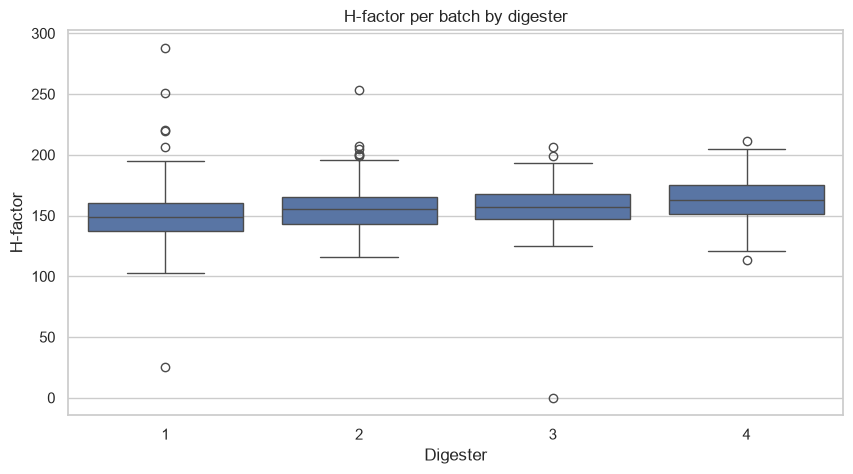

In [6]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=batches, x="digester", y="h_factor")
plt.title("H-factor per batch by digester")
plt.xlabel("Digester")
plt.ylabel("H-factor")
plt.show()

## 6. H-factor trend over time

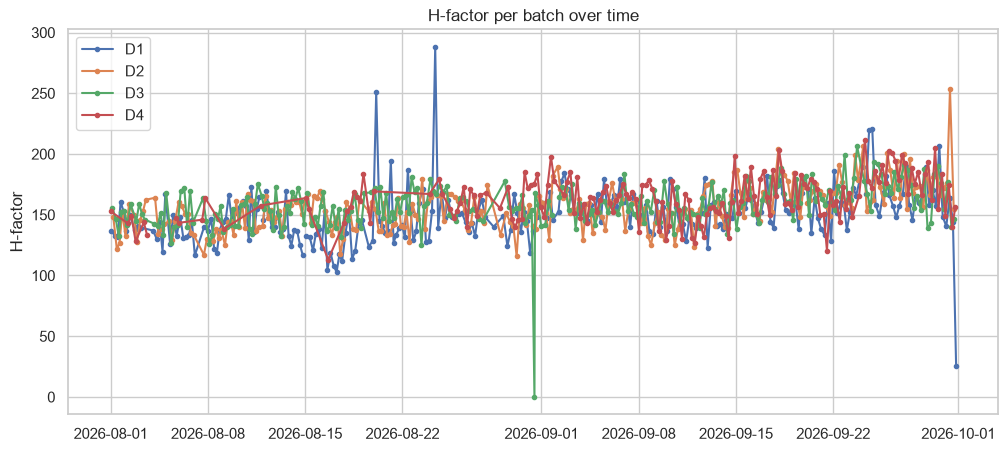

In [7]:
plt.figure(figsize=(12, 5))
for dig in [1, 2, 3, 4]:
    b = batches[batches["digester"] == dig]
    plt.plot(b["start"], b["h_factor"], marker=".", linestyle="-", label=f"D{dig}")
plt.legend()
plt.title("H-factor per batch over time")
plt.ylabel("H-factor")
plt.show()